# Learning a posterior from simulations

**A small, readable project on simulation-based inference (SBI), neural posterior
estimation (NPE), and normalizing flows.**

We will infer two unknown numbers, $\theta=(a,b)$, from 20 noisy measurements.
First we fit an ordinary line. Then we change one term in the simulator and get
a curved posterior. We write the flow ourselves using PyTorch, rather than
calling an inference library.

Read from top to bottom and use **Restart Kernel and Run All**. The saved copy
already contains the results. All training uses the CPU; the measured runtime
appears below. The network lives in `flow.py`; the simulator and training loop
stay here where you can see them.

Our workflow is:

1. Choose parameters from a prior, then simulate a dataset.
2. Train a conditional density on many such pairs.
3. Give the trained network one observed dataset and sample its posterior.
4. Compare with a reference posterior that we can calculate for these toy models.

In [1]:
from pathlib import Path
from copy import deepcopy
import json
import os
import time

PROJECT = Path.cwd()
OUTPUT = PROJECT / "results"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
# Keep plotting caches inside this project, including on restricted machines.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT / ".cache" / "matplotlib"))

import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")  # save figures without needing a desktop window
import matplotlib.pyplot as plt
from IPython.display import Image, display

from flow import AffineCoupling, ConditionalFlow

torch.set_num_threads(2)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

print("Python packages:", {"torch": torch.__version__,
                          "numpy": np.__version__, "matplotlib": matplotlib.__version__})
print("Device: CPU; PyTorch threads:", torch.get_num_threads())

def show_and_save(figure, name):
    """Keep a PNG for the notebook and a vector PDF for the report."""
    figure.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")
    figure.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{name}.png")))
    plt.close(figure)

Matplotlib is building the font cache; this may take a moment.


Python packages: {'torch': '2.7.1', 'numpy': '2.1.3', 'matplotlib': '3.10.3'}
Device: CPU; PyTorch threads: 2


## 1. The two simulators

Our independent priors match the slides:

$$a\sim U[-1,1],\qquad b\sim U[-2,2].$$

A **simulator** takes chosen parameters and generates fake measurements:

$$y_j=a+bt_j+c b^2+\varepsilon_j,\qquad
\varepsilon_j\sim N(0,0.25^2).$$

- $t_j$: known measurement locations, equally spaced between $-0.2$ and $0.2$.
- $y=(y_1,\ldots,y_{20})$: the dataset the network receives.
- $c=0$: ordinary linear regression; $a$ is the intercept and $b$ is the slope.
- $c=1$: the observed intercept is $a+b^2$. This model is nonlinear **in the
  parameters**, even though each simulated curve is still a straight line in $t$.

Why choose a narrow interval of measurement locations? It leaves appreciable
uncertainty about $b$. In the second example, changing $b$ can be offset by
changing $a$ along $a\approx\bar y-b^2$. That makes a curved posterior.

We treat the generated observations as our data. The true parameters are used
to generate and label the demonstration; **training does not receive the true
parameters of the observed dataset**.

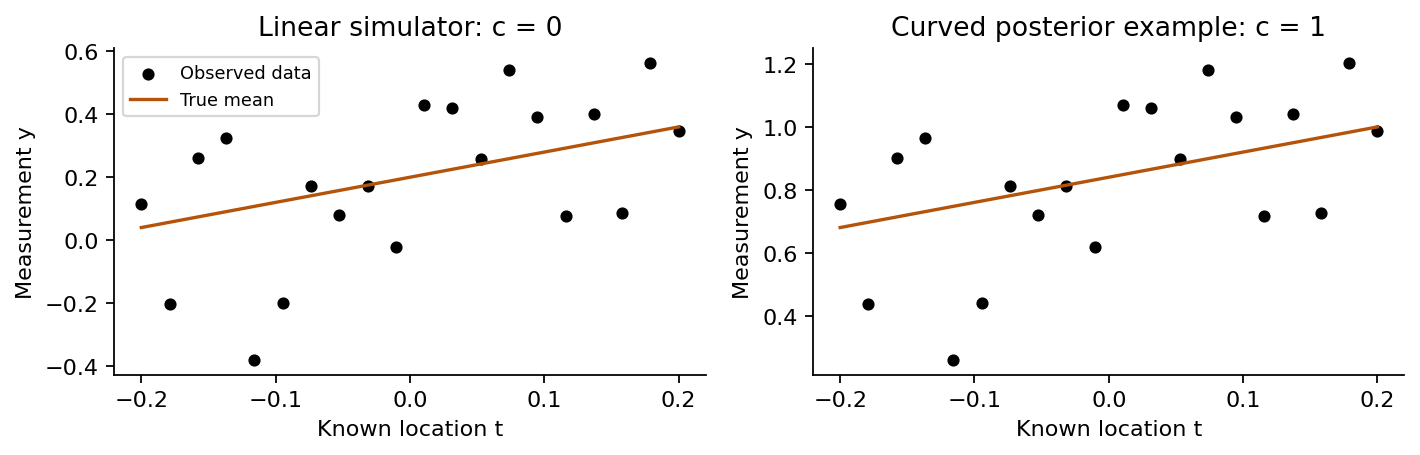

In [2]:
LOWER = np.array([-1.0, -2.0])
UPPER = np.array([1.0, 2.0])
LOCATIONS = np.linspace(-0.2, 0.2, 20)
NOISE_SD = 0.25
TRUE_THETA = np.array([0.2, 0.8])

# These are the main settings to change when experimenting.
NUM_SIMULATIONS = 20_000  # includes the 10% validation set
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 15
LEARNING_RATE = 1e-3
NUM_POSTERIOR_SAMPLES = 20_000
GRID_SIZE = 400

def simulate(theta, curvature, rng):
    """theta: (number of datasets, 2); returned data: (number of datasets, 20)."""
    theta = np.atleast_2d(theta)
    a = theta[:, 0:1]  # retain a column so NumPy can combine it with 20 locations
    b = theta[:, 1:2]
    mean_measurements = a + b * LOCATIONS + curvature * b**2
    noise = rng.normal(0.0, NOISE_SD, size=mean_measurements.shape)
    return mean_measurements + noise

observed = {}
for curvature in (0, 1):
    # Reusing this noise seed gives both examples the same measurement noise.
    y = simulate(TRUE_THETA, curvature, np.random.default_rng(42))[0]
    observed[curvature] = torch.tensor(y, dtype=torch.float32)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
for curvature, ax in enumerate(axes):
    truth = TRUE_THETA[0] + TRUE_THETA[1] * LOCATIONS + curvature * TRUE_THETA[1]**2
    ax.scatter(LOCATIONS, observed[curvature], color="black", s=20, label="Observed data")
    ax.plot(LOCATIONS, truth, color="#b45309", label="True mean")
    ax.set(title=["Linear simulator: c = 0", "Curved posterior example: c = 1"][curvature],
           xlabel="Known location t", ylabel="Measurement y")
axes[0].legend(fontsize=8)
fig.tight_layout()
show_and_save(fig, "observations")

## 2. What is the neural network learning?

NPE estimates a **conditional probability density** $q_\phi(\theta\mid y)$.
The symbol $\phi$ means all the network's trainable weights. The output is a
distribution over parameter pairs, not just one best-fitting pair.

We generate pairs $(\theta_i,y_i)$ with
$\theta_i\sim p(\theta)$ and $y_i\sim p(y\mid\theta_i)$, then minimize

$$\widehat{\mathcal L}(\phi)
=-\frac1N\sum_{i=1}^N\log q_\phi(\theta_i\mid y_i).$$

For each pair we ask: **does the density assign a high value to the parameters
that generated these data?** The population identity from your notes explains
why this targets a posterior:

$$\mathcal L(\phi)=H(\Theta\mid Y)
+\mathbb E_{p(y)}D_{\rm KL}\{p(\theta\mid y)\Vert q_\phi(\theta\mid y)\}.$$

The entropy term does not depend on $\phi$. Minimizing the loss therefore
minimizes an average posterior discrepancy. Finite training does not guarantee
an exact posterior at every observation. Densities can exceed one, so a negative
log-density loss can legitimately be negative.

## 3. One invertible coupling layer

A **tensor** is an array used by PyTorch. A **batch** is a group of examples
processed together. For a batch of size $B$:

| Quantity | Shape | Meaning |
|---|---|---|
| Parameters | `(B, 2)` | One $(a,b)$ pair per row |
| Observations | `(B, 20)` | One simulated dataset per row |
| Log densities | `(B,)` | One number per pair |

The flow starts with $z\sim N(0,I_2)$. One coupling layer keeps the first
coordinate and changes the second:

$$v_1=u_1,\qquad v_2=u_2\exp\{s(u_1,y)\}+h(u_1,y).$$

The small network predicts $s$ and $h$. Its weights need not be invertible:
the **whole transformation** is invertible because $v_1=u_1$. Its inverse is

$$u_1=v_1,\qquad u_2=(v_2-h(v_1,y))\exp\{-s(v_1,y)\}.$$

The Jacobian is triangular, so the forward log absolute determinant is $s$.
The inverse log determinant is $-s$. We alternate which coordinate is kept,
so both coordinates can change over six layers. Here is one actual layer:

In [3]:
torch.manual_seed(7)
demo_layer = AffineCoupling(observation_size=20, hidden_size=64, keep_coordinate=0)
# Layers start at the identity. Perturb the demo layer to make its action visible.
with torch.no_grad():
    demo_layer.network[-1].weight.normal_(mean=0.0, std=0.08)

u = torch.tensor([[0.5, -1.0], [-0.3, 0.7]])
context = torch.zeros(2, 20)
v, forward_log_det = demo_layer(u, context)
recovered_u, inverse_log_det = demo_layer.inverse(v, context)
print("Before:\n", u)
print("After:\n", v.detach())
print("Recovered:\n", recovered_u.detach())
print("Largest round-trip error:", float((u - recovered_u).abs().max().detach()))
print("Forward + inverse log determinant:", (forward_log_det + inverse_log_det).detach())

Before:
 tensor([[ 0.5000, -1.0000],
        [-0.3000,  0.7000]])
After:
 tensor([[ 0.5000, -0.8827],
        [-0.3000,  0.4737]])
Recovered:
 tensor([[ 0.5000, -1.0000],
        [-0.3000,  0.7000]])
Largest round-trip error: 5.960464477539063e-08
Forward + inverse log determinant: tensor([0., 0.])


## 4. Keeping parameters inside the prior bounds

Coupling layers produce an unbounded value $u$. A sigmoid puts it in our box:

$$\theta_j=\ell_j+(r_j-\ell_j)\operatorname{sigmoid}(u_j),\qquad
u_j=\log\frac{\theta_j-\ell_j}{r_j-\theta_j}.$$

Here $(\ell_1,\ell_2)=(-1,-2)$ and $(r_1,r_2)=(1,2)$. This is an invertible
map between $\mathbb R^2$ and the **interior** of the box; the boundary has
probability zero. Its forward log determinant is

$$\sum_j\left[\log(r_j-\ell_j)+\log\operatorname{sigmoid}(u_j)
+\log\operatorname{sigmoid}(-u_j)\right].$$

Every density calculation includes this term. We do not clip posterior samples
to the box: clipping would change their distribution. `log_prob` returns
$-\infty$ outside the box and at its endpoints.

To evaluate a density, the code runs **backward** through the transformations:

$$\log q_\phi(\theta\mid y)
=\log p_Z(z)+\log\left|\det\frac{\partial z}{\partial\theta}\right|.$$

To sample, it runs **forward** from Gaussian noise to parameters. Open `flow.py`
and read `AffineCoupling`, then `to_parameters`, `to_base`, `log_prob`, and `sample`.
The data are held fixed when differentiating the transformations.

## 5. Generate training pairs and train

One **epoch** is one pass through the training pairs. A batch loss is the average
negative log density for one group of pairs. `backward()` computes how each
weight affects that loss; `optimizer.step()` updates the weights.

We reserve 10% of the simulations for validation. Validation pairs do not update
the weights. We save the best validation model, stop if it fails to improve for
15 epochs, and restore that best model. Observation means and standard deviations
are computed on the training set only and saved with the weights.

**This function is the entire training procedure.** There is no likelihood,
posterior reference, or observed dataset in its inputs.

In [4]:
def make_training_pairs(curvature, seed):
    rng = np.random.default_rng(seed)
    theta = torch.tensor(rng.uniform(LOWER, UPPER, (NUM_SIMULATIONS, 2)),
                         dtype=torch.float32)
    # Very rarely, float32 rounding can put a prior draw exactly on an endpoint.
    # Redraw just those rows so the inverse sigmoid remains defined.
    at_boundary = ((theta <= torch.tensor(LOWER)) | (theta >= torch.tensor(UPPER))).any(1)
    while at_boundary.any():
        theta[at_boundary] = torch.tensor(
            rng.uniform(LOWER, UPPER, (int(at_boundary.sum()), 2)), dtype=torch.float32)
        at_boundary = ((theta <= torch.tensor(LOWER)) | (theta >= torch.tensor(UPPER))).any(1)
    data = torch.tensor(simulate(theta.numpy(), curvature, rng), dtype=torch.float32)
    return theta, data


def train_flow(theta, data, seed):
    torch.manual_seed(seed)
    started = time.perf_counter()
    order = torch.randperm(len(theta))
    split = int(0.9 * len(theta))
    train_rows, validation_rows = order[:split], order[split:]
    train_theta, train_data = theta[train_rows], data[train_rows]
    validation_theta, validation_data = theta[validation_rows], data[validation_rows]

    model = ConditionalFlow(observation_size=20, num_layers=6, hidden_size=64)
    model.fit_observation_standardization(train_data)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_loss = float("inf")
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        shuffle = torch.randperm(len(train_theta))
        total_training_loss = 0.0
        for rows in shuffle.split(BATCH_SIZE):
            loss = -model.log_prob(train_theta[rows], train_data[rows]).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite training loss; inspect this run.")
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0, error_if_nonfinite=True)
            optimizer.step()
            total_training_loss += loss.item() * len(rows)

        model.eval()
        with torch.no_grad():
            validation_loss = -model.log_prob(validation_theta, validation_data).mean().item()
        if not np.isfinite(validation_loss):
            raise FloatingPointError("Non-finite validation loss; inspect this run.")
        training_loss = total_training_loss / len(train_theta)
        history.append({"epoch": epoch, "training_nll": training_loss,
                        "validation_nll": validation_loss})

        if validation_loss < best_loss - 1e-4:
            best_loss = validation_loss
            best_weights = deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epoch == 1 or epoch % 10 == 0:
            print(f"Epoch {epoch:3d}: train NLL={training_loss: .3f}, "
                  f"validation NLL={validation_loss: .3f}", flush=True)
        if epochs_without_improvement >= PATIENCE:
            break

    model.load_state_dict(best_weights)
    model.eval()
    summary = {"best_epoch": best_epoch, "epochs_run": epoch,
               "best_validation_nll": best_loss,
               "training_seconds": time.perf_counter() - started,
               "training_pairs": len(train_theta), "validation_pairs": len(validation_theta)}
    print(f"Restored epoch {best_epoch}; training took {summary['training_seconds']:.1f} s.")
    return model, history, summary


--- LINEAR EXAMPLE ---


Parameter array: (20000, 2) ; data array: (20000, 20)


Epoch   1: train NLL= 0.940, validation NLL= 0.072


Epoch  10: train NLL=-0.895, validation NLL=-0.896


Epoch  20: train NLL=-0.955, validation NLL=-0.924


Epoch  30: train NLL=-1.017, validation NLL=-0.970


... (12 outputs left out)

Epoch  60: train NLL=-1.420, validation NLL=-1.350


Epoch  70: train NLL=-1.466, validation NLL=-1.437


Epoch  80: train NLL=-1.449, validation NLL=-1.398


Restored epoch 68; training took 20.6 s.


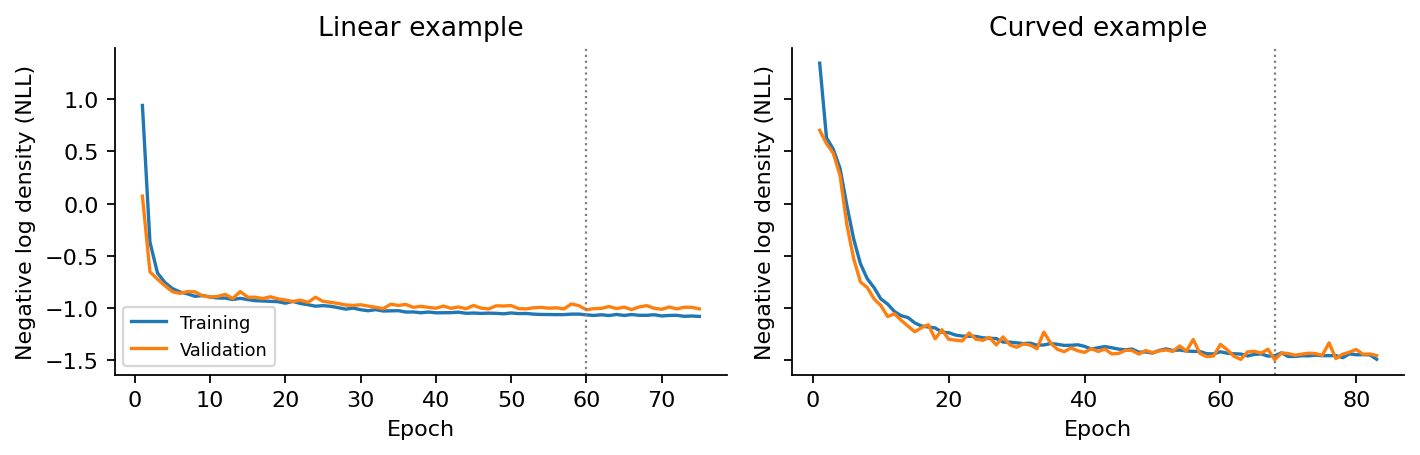

In [5]:
models, histories, training_summaries = {}, {}, {}
for curvature, name in [(0, "linear"), (1, "curved")]:
    print(f"\n--- {name.upper()} EXAMPLE ---", flush=True)
    theta, data = make_training_pairs(curvature, seed=100 + curvature)
    print("Parameter array:", tuple(theta.shape), "; data array:", tuple(data.shape), flush=True)
    model, history, summary = train_flow(theta, data, seed=110 + curvature)
    models[curvature], histories[curvature], training_summaries[curvature] = model, history, summary
    torch.save({"model_state_dict": model.state_dict(),
                "model_kwargs": {"observation_size": 20, "num_layers": 6, "hidden_size": 64},
                "curvature": curvature, "summary": summary}, OUTPUT / f"{name}_weights.pt")

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for curvature, ax in enumerate(axes):
    history = histories[curvature]
    ax.plot([r["epoch"] for r in history], [r["training_nll"] for r in history], label="Training")
    ax.plot([r["epoch"] for r in history], [r["validation_nll"] for r in history], label="Validation")
    ax.axvline(training_summaries[curvature]["best_epoch"], color="0.5", linestyle=":", lw=1)
    ax.set(title=["Linear example", "Curved example"][curvature], xlabel="Epoch",
           ylabel="Negative log density (NLL)")
axes[0].legend(fontsize=8)
fig.tight_layout()
show_and_save(fig, "training")

## 6. Calculate a reference posterior, only for checking

These toy likelihoods are easy to evaluate:

$$\log p(y\mid a,b)=-\frac{1}{2\sigma^2}
\sum_j[y_j-a-bt_j-cb^2]^2+\text{constant}.$$

Because the prior is constant inside its rectangle, Bayes' rule gives a reference
density proportional to this likelihood there. We evaluate it on a grid covering
the **entire prior box**, then normalize with cell area $\Delta a\,\Delta b$.
In the linear example this is a Gaussian restricted to the rectangle: a
**truncated Gaussian**, not an unrestricted Gaussian.

NPE did not use this likelihood during training. We deliberately chose tractable
toy examples so that we can check whether the learned result is accurate. In a
real SBI problem this checking calculation may be unavailable.

We use midpoint grids so no point lies on an endpoint of the prior. A second grid
with twice as many points along each axis checks quadrature accuracy.

In [6]:
def reference_posterior(observation, curvature, grid_size):
    a = LOWER[0] + (np.arange(grid_size) + 0.5) * (UPPER[0] - LOWER[0]) / grid_size
    b = LOWER[1] + (np.arange(grid_size) + 0.5) * (UPPER[1] - LOWER[1]) / grid_size
    aa, bb = np.meshgrid(a, b, indexing="ij")
    points = np.column_stack([aa.ravel(), bb.ravel()])
    log_likelihood = np.empty(len(points))
    y = np.asarray(observation, dtype=np.float64)
    for start in range(0, len(points), 4096):
        batch = points[start : start + 4096]
        predicted = (batch[:, 0:1] + batch[:, 1:2] * LOCATIONS
                     + curvature * batch[:, 1:2]**2)
        log_likelihood[start : start + len(batch)] = -0.5 * (((y - predicted) / NOISE_SD)**2).sum(1)
    unnormalized = np.exp(log_likelihood - log_likelihood.max())
    area = np.prod(UPPER - LOWER) / grid_size**2
    density = (unnormalized / (unnormalized.sum() * area)).reshape(grid_size, grid_size)
    return {"a": a, "b": b, "points": points, "area": area, "density": density}


@torch.no_grad()
def learned_density_on_grid(model, observation, grid):
    log_density = []
    for points in np.array_split(grid["points"], max(1, len(grid["points"]) // 4096)):
        theta = torch.tensor(points, dtype=torch.float32)
        log_density.append(model.log_prob(theta, observation).numpy())
    # IMPORTANT: do not divide this density by its grid integral.
    return np.exp(np.concatenate(log_density).astype(np.float64)).reshape(grid["density"].shape)


def grid_statistics(grid):
    probabilities = grid["density"] * grid["area"]
    means, standard_deviations, intervals = [], [], []
    for values, weights in [(grid["a"], probabilities.sum(1)),
                            (grid["b"], probabilities.sum(0))]:
        mean = float(np.sum(values * weights))
        means.append(mean)
        standard_deviations.append(float(np.sqrt(np.sum((values - mean)**2 * weights))))
        # Midpoint CDF interpolation avoids a half-cell shift of the quantiles.
        midpoint_cdf = np.cumsum(weights) - 0.5 * weights
        intervals.append(np.interp([0.05, 0.95], midpoint_cdf, values).tolist())
    return {"mean": means, "sd": standard_deviations, "interval90": intervals}


references, fine_references, learned_grids, samples, metrics = {}, {}, {}, {}, {}
for curvature, name in [(0, "linear"), (1, "curved")]:
    grid = reference_posterior(observed[curvature], curvature, GRID_SIZE)
    fine_grid = reference_posterior(observed[curvature], curvature, 2 * GRID_SIZE)
    learned = learned_density_on_grid(models[curvature], observed[curvature], grid)
    fine_learned = learned_density_on_grid(models[curvature], observed[curvature], fine_grid)
    torch.manual_seed(200 + curvature)
    draws = models[curvature].sample(NUM_POSTERIOR_SAMPLES, observed[curvature]).numpy()
    references[curvature], fine_references[curvature] = grid, fine_grid
    learned_grids[curvature], samples[curvature] = learned, draws
    reference_stats, fine_stats = grid_statistics(grid), grid_statistics(fine_grid)
    total_variation = 0.5 * np.sum(np.abs(grid["density"] - learned)) * grid["area"]
    fine_tv = 0.5 * np.sum(np.abs(fine_grid["density"] - fine_learned)) * fine_grid["area"]
    mass = float(np.sum(learned) * grid["area"])
    fine_mass = float(np.sum(fine_learned) * fine_grid["area"])
    mean_change = float(np.max(np.abs(np.array(reference_stats["mean"]) - fine_stats["mean"])))
    interval_change = float(np.max(np.abs(np.array(reference_stats["interval90"]) - fine_stats["interval90"])))
    # These assertions check the numerical REFERENCE, not a desired neural accuracy.
    assert mean_change < 0.001, "Refine the reference grid further."
    assert interval_change < 0.005, "Refine the reference quantiles further."
    assert np.isfinite(fine_learned).all(), "Invalid learned density on the grid."
    assert ((draws > LOWER) & (draws < UPPER)).all(), "A sample reached a prior boundary."
    metrics[name] = {
        **training_summaries[curvature],
        "reference": fine_stats,
        "learned": {"mean": draws.mean(0).tolist(), "sd": draws.std(0).tolist(),
                    "interval90": np.quantile(draws, [0.05, 0.95], axis=0).T.tolist()},
        "grid_mass_400": mass, "grid_mass_800": fine_mass,
        "grid_total_variation_400": float(total_variation),
        "grid_total_variation_800": float(fine_tv),
        "reference_mean_grid_change": mean_change,
        "reference_interval_grid_change": interval_change,
        "learned_mass_grid_change": abs(fine_mass - mass),
        "total_variation_grid_change": float(abs(fine_tv - total_variation)),
    }
    np.savez_compressed(OUTPUT / f"{name}_posterior.npz", samples=draws,
                        observation=observed[curvature].numpy(),
                        a=grid["a"], b=grid["b"], reference_density=grid["density"],
                        learned_density=learned)
    print(f"\n{name}: learned integral={fine_mass:.5f}; total variation={fine_tv:.4f}")
    for j, parameter in enumerate(["a", "b"]):
        learned_stats = metrics[name]["learned"]
        print(f"  {parameter}: reference mean={fine_stats['mean'][j]: .3f}, "
              f"learned mean={learned_stats['mean'][j]: .3f}; "
              f"90% intervals: reference={np.round(fine_stats['interval90'][j], 3)}, "
              f"learned={np.round(learned_stats['interval90'][j], 3)}")
    print(f"  Grid refinement: reference mean change={mean_change:.2g}, "
          f"interval change={interval_change:.2g}, TV change={abs(fine_tv-total_variation):.2g}")


linear: learned integral=1.00000; total variation=0.1220
  a: reference mean= 0.192, learned mean= 0.204; 90% intervals: reference=[0.1   0.284], learned=[0.115 0.294]
  b: reference mean= 1.073, learned mean= 1.102; 90% intervals: reference=[0.338 1.767], learned=[0.363 1.805]
  Grid refinement: reference mean change=1.2e-06, interval change=0.00012, TV change=3e-06



curved: learned integral=0.99997; total variation=0.2207
  a: reference mean=-0.044, learned mean= 0.079; 90% intervals: reference=[-0.877  0.754], learned=[-0.814  0.782]
  b: reference mean= 0.878, learned mean= 0.799; 90% intervals: reference=[0.269 1.307], learned=[0.27  1.264]
  Grid refinement: reference mean change=1.6e-07, interval change=6.1e-05, TV change=4.8e-05


## 7. Compare posterior shapes

Solid black contours show the reference posterior. Dashed blue contours show
the learned posterior. The contour lines enclose approximately 50% and 90% of
the reference or learned probability, respectively. Gray dots are learned
posterior samples; the orange cross marks the generating parameters.

Contours alone can hide errors. Read the marginal plots and numerical
discrepancies too. A **90% marginal credible interval** contains 90% of one
parameter's posterior mass; it is not a joint 90% region for both parameters.

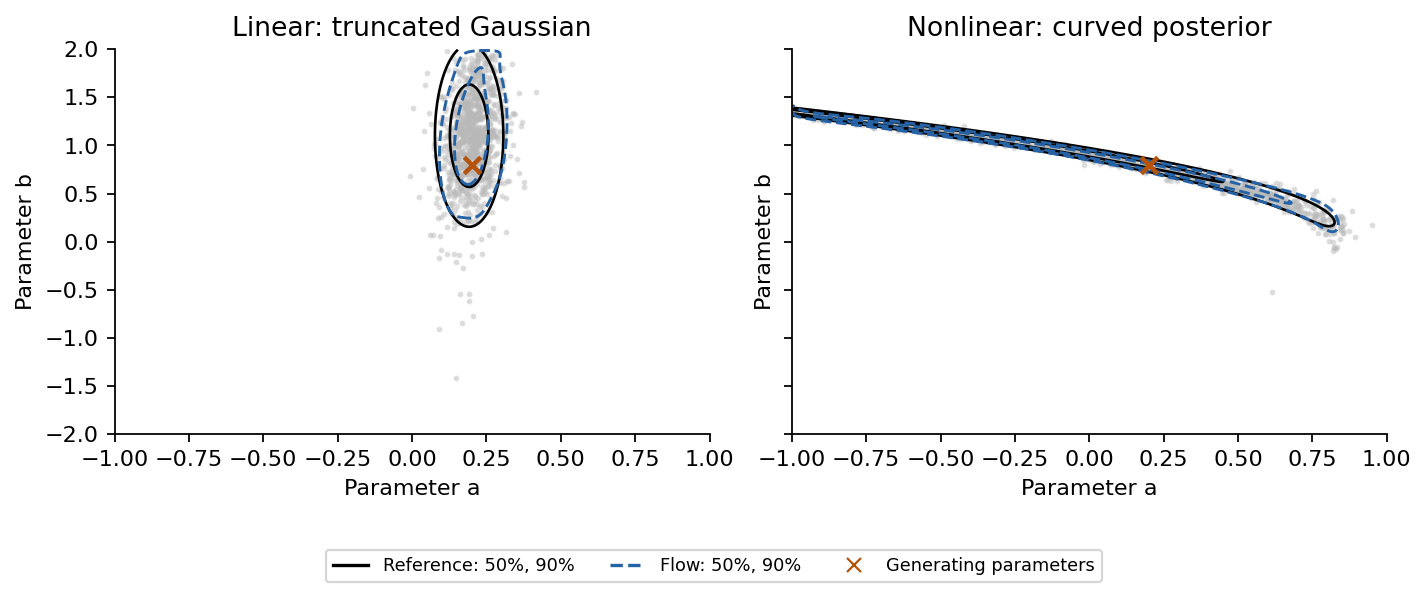

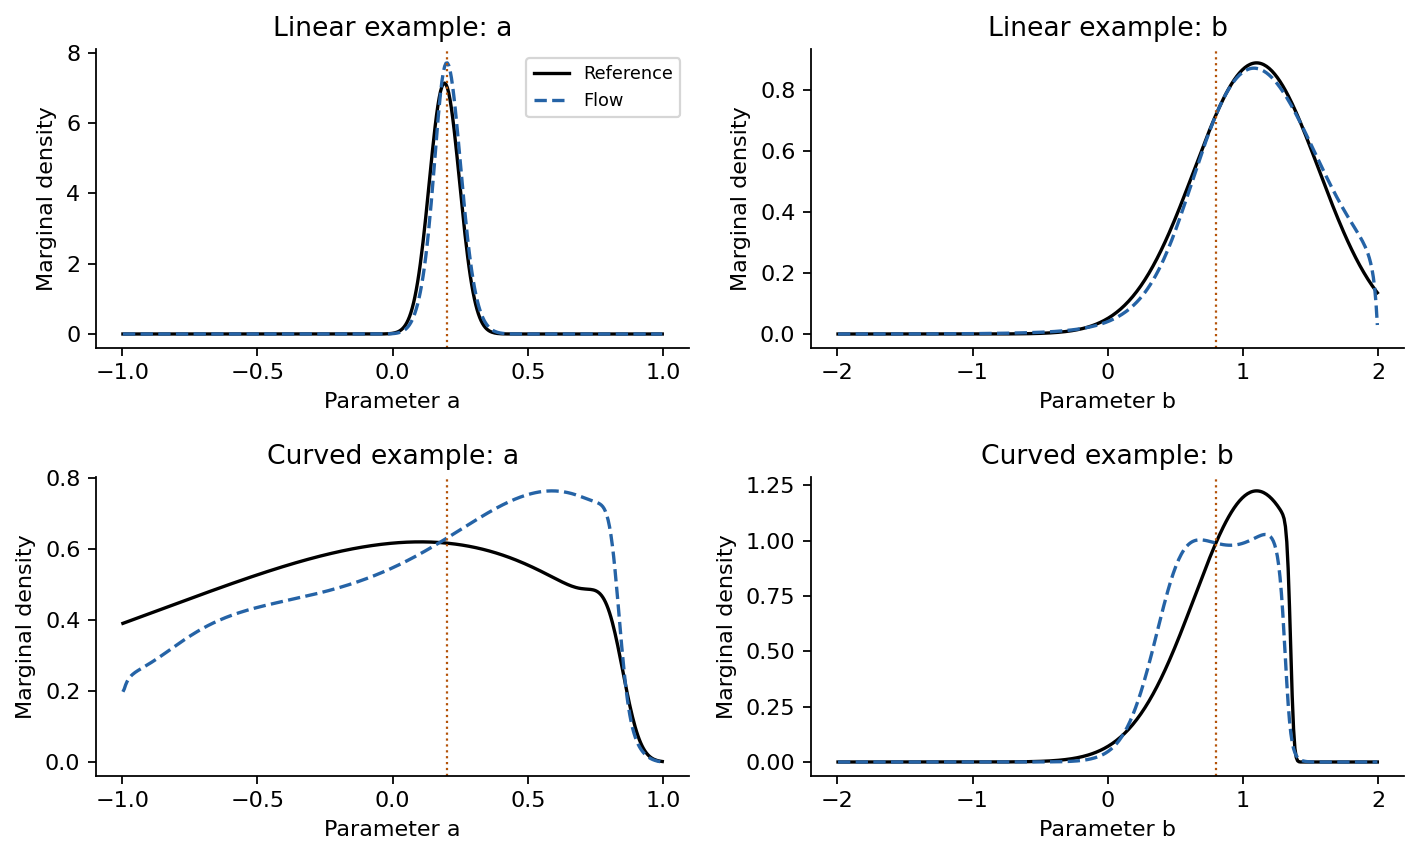

In [7]:
def contour_levels(density, area):
    sorted_density = np.sort(density.ravel())[::-1]
    cumulative_mass = np.cumsum(sorted_density) * area
    # Absolute mass, with no normalization of the learned grid values.
    if cumulative_mass[-1] < 0.90:
        raise ValueError("Grid has less than 90% mass; inspect before drawing contours.")
    return sorted([float(sorted_density[np.searchsorted(cumulative_mass, p)])
                   for p in [0.50, 0.90]])

from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), sharex=True, sharey=True)
for curvature, ax in enumerate(axes):
    grid, learned = references[curvature], learned_grids[curvature]
    draws = samples[curvature]
    ax.scatter(draws[::20, 0], draws[::20, 1], color="0.72", s=3, alpha=0.35, rasterized=True)
    ax.contour(grid["a"], grid["b"], grid["density"].T,
               levels=contour_levels(grid["density"], grid["area"]), colors="black", linewidths=1.2)
    ax.contour(grid["a"], grid["b"], learned.T,
               levels=contour_levels(learned, grid["area"]), colors="#2563a6",
               linewidths=1.3, linestyles="--")
    ax.scatter(*TRUE_THETA, marker="x", color="#b45309", s=55, linewidths=2, zorder=5)
    ax.set(xlim=(-1, 1), ylim=(-2, 2), xlabel="Parameter a", ylabel="Parameter b",
           title=["Linear: truncated Gaussian", "Nonlinear: curved posterior"][curvature])
fig.legend(handles=[Line2D([], [], color="black", label="Reference: 50%, 90%"),
                    Line2D([], [], color="#2563a6", linestyle="--", label="Flow: 50%, 90%"),
                    Line2D([], [], color="#b45309", marker="x", linestyle="", label="Generating parameters")],
           loc="lower center", ncol=3, fontsize=8)
fig.tight_layout(rect=[0, 0.09, 1, 1])
show_and_save(fig, "posterior_comparison")

fig, axes = plt.subplots(2, 2, figsize=(9, 5.5))
for curvature in (0, 1):
    grid = references[curvature]
    reference_marginals = [grid["density"].sum(1) * (4 / GRID_SIZE),
                           grid["density"].sum(0) * (2 / GRID_SIZE)]
    learned_marginals = [learned_grids[curvature].sum(1) * (4 / GRID_SIZE),
                         learned_grids[curvature].sum(0) * (2 / GRID_SIZE)]
    for j, parameter in enumerate(["a", "b"]):
        ax = axes[curvature, j]
        values = grid[parameter]
        ax.plot(values, reference_marginals[j], color="black", label="Reference")
        ax.plot(values, learned_marginals[j], color="#2563a6", linestyle="--", label="Flow")
        ax.axvline(TRUE_THETA[j], color="#b45309", linestyle=":", lw=1)
        ax.set(xlabel=f"Parameter {parameter}", ylabel="Marginal density",
               title=f"{['Linear', 'Curved'][curvature]} example: {parameter}")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
show_and_save(fig, "marginals")

## 8. Posterior predictive check

For each posterior draw $(a,b)$, generate a new noisy dataset. The blue band is
the pointwise central 90% range of those **future noisy measurements**, not a
confidence band for the true mean. The narrower dashed curves describe
uncertainty in the noise-free mean. The data used for inference are plotted too;
this is a model check, not an independent prediction test.

The scalar discrepancy above is total variation:

$$\operatorname{TV}(p,q)=\tfrac12\int|p(\theta\mid y)-q(\theta\mid y)|\,d\theta.$$

It ranges from zero (agreement) to one (complete separation). We approximate it
over the entire prior box and report the grid integral of $q$ separately. We
**never renormalize the learned density on the grid**. A near-one integral checks
quadrature; it does not establish posterior accuracy.

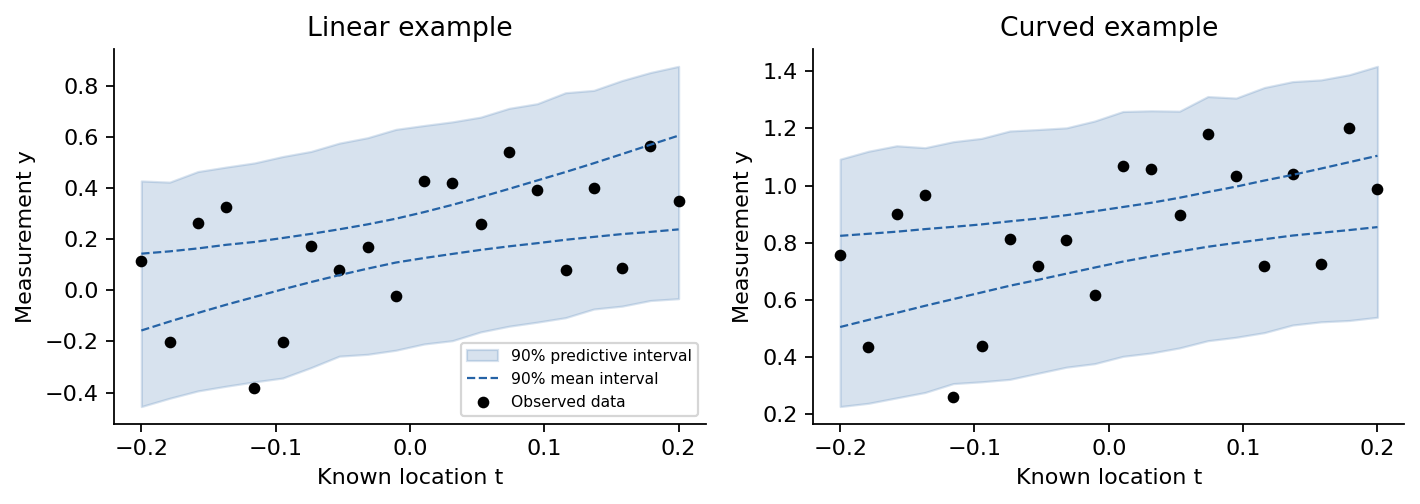

Saved figures, posterior arrays, weights, histories and metrics under: /Users/iu/Documents/UOFT/STA355/STA492/results
Total training time (seconds): 40.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharex=True)
for curvature, ax in enumerate(axes):
    draws = samples[curvature][:5000]
    a, b = draws[:, 0:1], draws[:, 1:2]
    mean_curves = a + b * LOCATIONS + curvature * b**2
    rng = np.random.default_rng(300 + curvature)
    new_data = mean_curves + rng.normal(0, NOISE_SD, mean_curves.shape)
    lower, upper = np.quantile(new_data, [0.05, 0.95], axis=0)
    mean_lower, mean_upper = np.quantile(mean_curves, [0.05, 0.95], axis=0)
    ax.fill_between(LOCATIONS, lower, upper, color="#2563a6", alpha=0.18,
                    label="90% predictive interval")
    ax.plot(LOCATIONS, mean_lower, color="#2563a6", linestyle="--", lw=1,
            label="90% mean interval")
    ax.plot(LOCATIONS, mean_upper, color="#2563a6", linestyle="--", lw=1)
    ax.scatter(LOCATIONS, observed[curvature], color="black", s=18, label="Observed data")
    ax.set(title=["Linear example", "Curved example"][curvature],
           xlabel="Known location t", ylabel="Measurement y")
axes[0].legend(fontsize=7, loc="lower right")
fig.tight_layout()
show_and_save(fig, "posterior_predictive")

settings = {"num_simulations": NUM_SIMULATIONS, "batch_size": BATCH_SIZE,
            "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "learning_rate": LEARNING_RATE,
            "num_posterior_samples": NUM_POSTERIOR_SAMPLES, "grid_sizes": [GRID_SIZE, 2*GRID_SIZE],
            "noise_sd": NOISE_SD, "locations": LOCATIONS.tolist(),
            "true_theta": TRUE_THETA.tolist(), "lower": LOWER.tolist(), "upper": UPPER.tolist(),
            "observation_seed": 42, "simulation_seeds": [100, 101],
            "training_seeds": [110, 111], "sampling_seeds": [200, 201],
            "torch_version": torch.__version__, "numpy_version": np.__version__,
            "matplotlib_version": matplotlib.__version__, "torch_threads": torch.get_num_threads()}
with open(OUTPUT / "metrics.json", "w") as file:
    json.dump({"settings": settings, "experiments": metrics}, file, indent=2, allow_nan=False)
with open(OUTPUT / "training_history.json", "w") as file:
    json.dump({str(c): h for c, h in histories.items()}, file, indent=2, allow_nan=False)

print("Saved figures, posterior arrays, weights, histories and metrics under:", OUTPUT)
print("Total training time (seconds):", round(sum(s["training_seconds"] for s in training_summaries.values()), 1))

## 9. Reuse a trained model without training again

The model is **amortized**: one trained network can process different observed
datasets from the same simulator and prior. Replacing `new_observation` below
does not update the weights. It must still be a vector of 20 measurements at
the same known locations, with the same noise model.

In [9]:
checkpoint = torch.load(OUTPUT / "curved_weights.pt", map_location="cpu", weights_only=True)
reloaded_model = ConditionalFlow(**checkpoint["model_kwargs"])
reloaded_model.load_state_dict(checkpoint["model_state_dict"])
reloaded_model.eval()

# Here we reuse the existing data just to demonstrate the saved interface.
new_observation = observed[1]
torch.manual_seed(401)
new_samples = reloaded_model.sample(1000, new_observation)
log_densities = reloaded_model.log_prob(new_samples[:5], new_observation)
print("Posterior samples:", tuple(new_samples.shape))
print("Five log densities:", log_densities.detach().numpy())
# Verify that saving and reloading did not change density evaluation.
torch.testing.assert_close(log_densities, models[1].log_prob(new_samples[:5], new_observation))

Posterior samples: (1000, 2)
Five log densities: [0.7946503 1.9891496 1.9243445 0.7500887 1.3821242]


## What to take away

- **SBI** is the broad idea of using simulations for inference. **NPE** is the
  particular strategy of learning the posterior density from simulated pairs.
  **A normalizing flow** is the density model we chose for that strategy.
- The flow learns distributions. It does not identify a unique parameter pair
  when multiple pairs remain consistent with the observations.
- A correct change-of-variables calculation gives a normalized learned model;
  it does not make the learned model equal to the true posterior.
- This is one training seed and one observed dataset per example. It is an
  educational demonstration, not a repeated-simulation calibration study.
  A credible interval containing the generating value once is not a coverage test.
- To explore: change `TRUE_THETA`, widen `LOCATIONS`, or change the simulation
  budget. Changes to the prior, simulator, locations, or noise model require
  regenerating the training pairs and training again. A new observed dataset
  under the same setup does not.

### References

1. Dinh, Sohl-Dickstein and Bengio (2017),
   [Density estimation using Real NVP](https://arxiv.org/abs/1605.08803).
2. Papamakarios and Murray (2016),
   [Fast epsilon-free inference of simulation models with Bayesian conditional density estimation](https://proceedings.neurips.cc/paper/2016/hash/6aca97005c68f1206823815f66102863-Abstract.html).

We use a single round of prior simulations. The sequential proposal procedure
from the second paper is outside this small project.